In [81]:
import pandas as pd

# Specify the file path
file_path = r"C:\Users\Lenovo\Documents\Cursos\DataAnalysis-IronHack\Week5\Day1\lab-eda-univariate\amz_uk_price_prediction_dataset.csv"

# Read the CSV file
df = pd.read_csv(file_path)

# Display the first few rows of the DataFrame
display(df.head())

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.70,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.70,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.60,1881,17.99,False,0,Hi-Fi Speakers


In [82]:
df.shape

(2443651, 9)

In [83]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [84]:
filtered_df = df[df['boughtInLastMonth'] != 0]
display(filtered_df)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
29,30,B01N4V4X5M,"Upgraded, Anker Soundcore Boost Bluetooth Spea...",4.70,29387,39.98,False,600,Hi-Fi Speakers
32,33,B07WVP26FR,"Kolaura Portable Wireless Speaker, Bluetooth 5...",4.40,2493,15.99,False,1000,Hi-Fi Speakers
92,93,B083K77PZL,"W-KING Bluetooth Speaker, 50W Speakers Wireles...",4.60,2979,65.59,False,200,Hi-Fi Speakers
143,144,B09J47Y789,XSOUND Portable Bluetooth Speaker Wireless 24W...,4.40,804,22.99,False,200,Hi-Fi Speakers
160,161,B08FCDFHLB,"soundcore Anker Mini 3 Bluetooth Speaker, Bass...",4.70,3208,34.99,False,200,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2440110,2822173,B078XKSQ41,PRO-SPIN Portable Table Tennis Set | Premium A...,4.60,5414,29.99,False,300,Table Tennis
2440120,2822184,B0841XR4TK,PRO-SPIN Table Tennis Bat With Pro Carbon Fibr...,4.60,3781,42.99,True,100,Table Tennis
2442705,2826691,B084ZV9N5X,PRO-SPIN Portable Table Tennis Set | Premium A...,4.60,5414,16.99,False,100,Table Tennis
2442985,2827259,B078XLCMRD,PRO SPIN Ping Pong Balls - 3-Star 40+ Table Te...,4.60,9218,8.99,False,400,Table Tennis


In [85]:
df.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

In [86]:
df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [87]:
potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 50]
potential_categorical_from_numerical

,stars,boughtInLastMonth
0,4.70,0
1,4.70,0
2,4.70,0
3,4.70,0
4,4.60,0
...,...,...
2443646,0.00,0
2443647,0.00,0
2443648,0.00,0
2443649,4.30,0


In [88]:
df.select_dtypes("object").columns

Index(['asin', 'title', 'category'], dtype='object')

In [89]:
df.select_dtypes("object").nunique().sort_values(ascending=False) 

asin        2222742
title       2077591
category        296
dtype: int64

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category,stars_category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers,Excellent
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers,Excellent
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers,Excellent
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers,Excellent
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers,Excellent


In [90]:
df['uid'] = df['uid'].astype('category')

In [91]:
df_categorical = pd.concat([df.select_dtypes("object")], axis=1)

In [92]:
df_numerical = df.select_dtypes("number")

In [93]:
df.isnull().sum().sort_values(ascending=False)

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [94]:
df.columns[df.isnull().mean() > 0.8]

Index([], dtype='object')

In [95]:
frequency_table = df['category'].value_counts()

frequency_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [96]:
df_top5=frequency_table.head(5)
df_top5

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [97]:
my_table = pd.crosstab(index = df_categorical["category"], 
                              columns="count")      
my_table = my_table.sort_values(by="count", ascending=False)
my_table.head(5)

col_0,count
category,
Sports & Outdoors,836265
Beauty,19312
"Handmade Clothing, Shoes & Accessories",19229
Bath & Body,19092
Birthday Gifts,18978


In [98]:
import seaborn as sns 
ax=sns.barplot(y=df_top5.index, x=df_top5.values, palette="Set3", hue=df_top5.index, legend='full' )
sns.move_legend(ax, "lower right")

In [99]:
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline

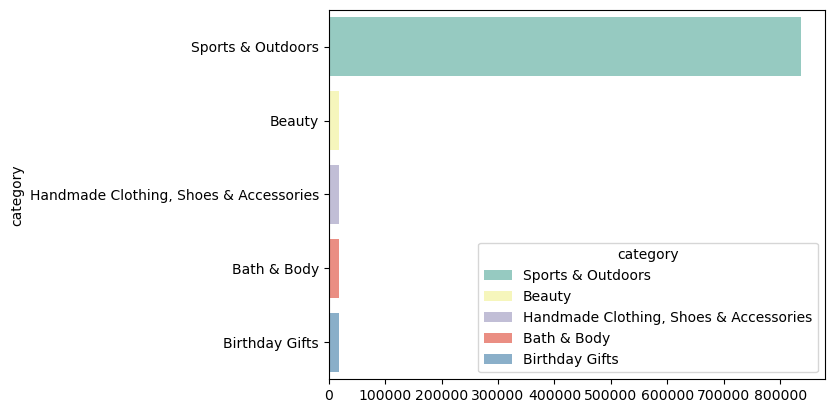

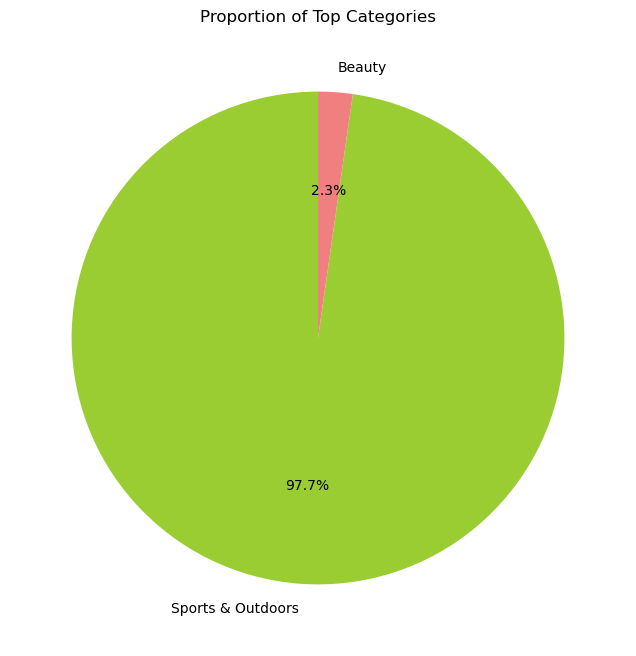

In [100]:
category_counts = df['category'].value_counts()
top_categories_count = 2
top_categories = category_counts.nlargest(top_categories_count)

# Step 2: Plot proportions of top categories using a pie chart
plt.figure(figsize=(8, 8))
top_categories.plot.pie(autopct='%1.1f%%', startangle=90, labels=top_categories.index, colors=['yellowgreen', 'lightcoral'])
plt.title('Proportion of Top Categories')
plt.ylabel('')  # Hide y-label for clarity
plt.show()

In [101]:
pd.set_option('display.float_format', '{:.2f}'.format)
df.describe()

,stars,reviews,price,boughtInLastMonth
count,2443651.00,2443651.00,2443651.00,2443651.00
mean,2.15,480.63,89.24,25.90
std,2.19,5944.12,345.61,240.48
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,9.99,0.00
50%,0.00,0.00,19.09,0.00
75%,4.40,59.00,45.99,0.00
max,5.00,1356658.00,100000.00,50000.00


In [102]:
df['price'].mode()

0   9.99
Name: price, dtype: float64

In [103]:
df['price'].median()

19.09

In [104]:
variance_price = df['price'].var()

In [105]:
#The average price is a lot higher than the mode, this can be explained by the sensitivity of the mean to extreme values. A few products with very high prices may affect the result of the mean, althoughth emajority of products are sstill of a lower price. 

In [106]:
#The standard deviation, a measure of the amount of variation or dispersion in the sale prices, is approximately 345. This indicates that sale prices can vary significantly from the average.

In [107]:
#The minimum and maximum sale prices are 0 and 100,000, respectively, highlighting a wide range of product values in the dataset.

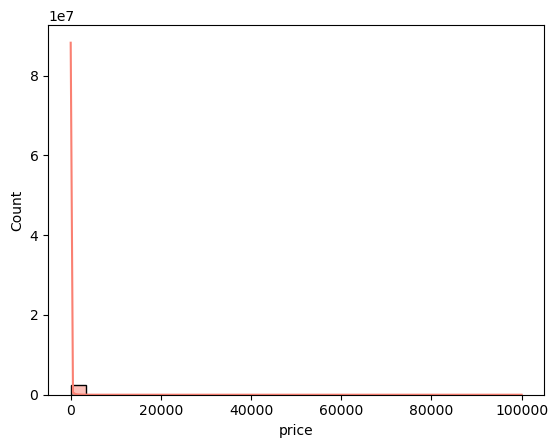

In [128]:
fig, axes = plt.subplots()
sns.histplot(df['price'], kde=True, bins=30, color="salmon", ax=axes);
plt.show()

In [ ]:
#it is hard to read because of the large amount of values. It could be corrected creating bins to classify groups of values. 

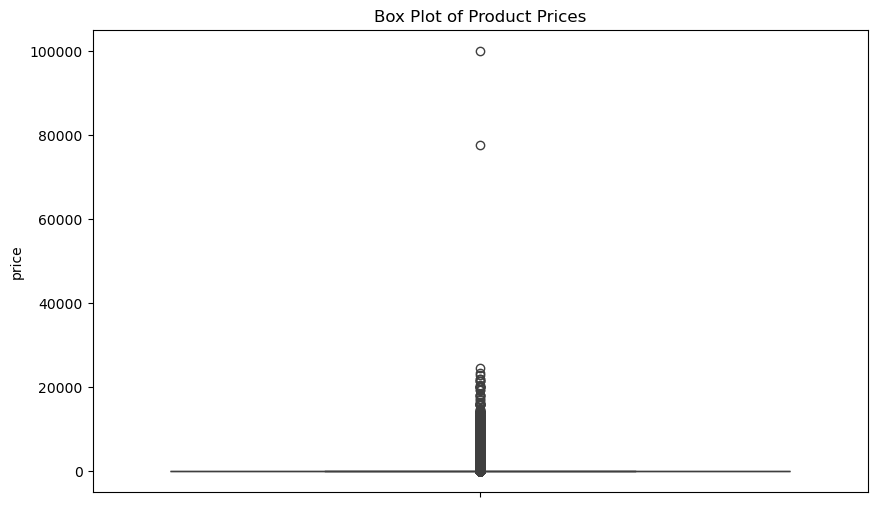

In [114]:
plt.figure(figsize=(10, 6))
sns.boxplot(y=df['price'])
plt.title('Box Plot of Product Prices')
plt.ylabel('price')
plt.show()

In [119]:
mean_stars = df['stars'].mean()

mean_stars

np.float64(2.152836472966065)

In [120]:
median_stars = df['stars'].median()
median_stars


0.0

In [ ]:
#the average rating is rather negative

In [121]:
mode_stars = df['stars'].mode()[0]
mode_stars

np.float64(0.0)

In [116]:
variance = df['stars'].var()
std_dev = df['stars'].std()
min_stars = df['stars'].min()
max_stars = df['stars'].max()
range_stars = max_stars - min_stars
quantiles_stars = df['stars'].quantile([0.25, 0.5, 0.75])

variance, std_dev, min_stars, max_stars, range_stars, quantiles_stars

(4.81743402976196,
 2.1948653785054697,
 0.0,
 5.0,
 5.0,
 0.25   0.00
 0.50   0.00
 0.75   4.40
 Name: stars, dtype: float64)

In [122]:
df.describe()

,stars,reviews,price,boughtInLastMonth
count,2443651.00,2443651.00,2443651.00,2443651.00
mean,2.15,480.63,89.24,25.90
std,2.19,5944.12,345.61,240.48
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,9.99,0.00
50%,0.00,0.00,19.09,0.00
75%,4.40,59.00,45.99,0.00
max,5.00,1356658.00,100000.00,50000.00


In [123]:
skewness_price = df['stars'].skew()
kurtosis_price = df['stars'].kurtosis()

skewness_price, kurtosis_price

(np.float64(0.08120735761080985), np.float64(-1.9260061280432985))

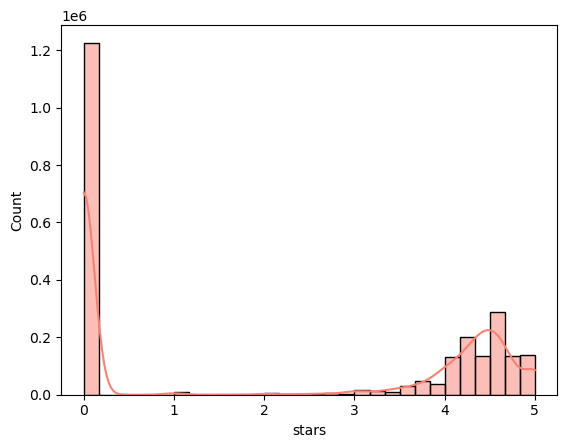

In [124]:
fig, axes = plt.subplots()
sns.histplot(df['stars'], kde=True, bins=30, color="salmon", ax=axes);
plt.show()

In [ ]:
#the most common rating is 0